## 1. Libraries and Setup

Import the libraries used for data loading, inspection, visualization, preprocessing, class balancing, scaling, and model evaluation.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler , OrdinalEncoder , OneHotEncoder 
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report , confusion_matrix

## 2. Load the Dataset

Load the Titanic training and test CSV files into pandas DataFrames. The following steps inspect and prepare the training data for modeling.

In [2]:
X_df = pd.read_csv(r"C:\Users\DELL\Downloads\train.csv")
df = pd.read_csv(r"C:\Users\DELL\Downloads\test.csv")

## 3. Preview the Dataset

`head()` displays the first rows so we can inspect the columns and example values before preprocessing.

In [3]:
X_df.head(30)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [4]:
print(X_df["Parch"].value_counts())
print(X_df["SibSp"].value_counts())

Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64
SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64


## 4. Dataset Information

`info()` shows the row count, column names, data types, and non-null counts. This helps identify missing values and unexpected data types.

In [5]:
X_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


## 5. Check Duplicate Rows

Count duplicate rows after excluding `PassengerId`. Because it is a unique identifier, it should not prevent otherwise identical records from being detected.

In [6]:
duplicate_count = X_df.drop(
    columns=["PassengerId"]
).duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


## 6. Summary Statistics

`describe()` summarizes numeric columns using count, mean, standard deviation, minimum, quartiles, and maximum. These values can help reveal unusual ranges and possible outliers.

In [7]:
X_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 7. Check Dataset Shape

`shape` returns the number of rows and columns. It provides a quick way to check the dataset size.

In [8]:
X_df.shape

(891, 12)

## 8. Count Missing Values

`isnull().sum()` counts missing values in each column. The results help decide which columns need missing-value treatment.

In [9]:
X_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## 9. Inspect Cabin Missingness

Calculate the percentage of missing values in `Cabin`. This helps assess whether the column should be retained, converted into a simple indicator, or dropped.

In [10]:
X_df["Cabin"].isnull().mean() * 100

np.float64(77.10437710437711)

## 10. Separate Features and Target

Separate the input features (`X`) from the target (`y`). `Survived` is the value the model will predict, while `PassengerId` is excluded from the features.

In [11]:
X = X_df.drop(["Survived","PassengerId"], axis=1)
y = X_df["Survived"]

## 11. Drop Name and Ticket

Remove `Name` and `Ticket` from the feature set because their raw text values are not used directly in this workflow.

In [12]:
X = X.drop(["Name", "Ticket"] , axis=1)

## 12. Inspect Target Distribution

`value_counts()` shows how many passengers belong to each `Survived` class. This helps identify class imbalance before model training.

In [13]:
y.value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

## 13. Handle Cabin

The current code drops `Cabin` because it contains many missing values. An alternative would be to create a `HasCabin` indicator first, but that alternative is not performed in this notebook.

In [14]:
X.drop(columns=["Cabin"] , inplace=True)

## 14. Review Feature Columns

Display the remaining feature names to confirm which columns are available for preprocessing and modeling.

In [15]:
X.columns

Index(['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked'], dtype='object')

## 15. Split Training and Testing Data

`train_test_split()` separates the data into training and testing sets. `stratify=y` preserves approximately the same target-class proportions in both sets, and `random_state` makes the split reproducible.

In [16]:
X_train , X_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
) 

## 16. Impute Missing Values in Training Data

Fill missing numeric training values with each column's training mean and missing categorical values with its most frequent training value. These training-set statistics are then reused for the test data.

In [17]:
for column in X_train.columns:
    if X_train[column].dtype in ["int64" , "float64"]:
         X_train[column] = X_train[column].fillna(X_train[column].mean())
    elif X_train[column].dtype == "object":
         X_train[column] = X_train[column].fillna(X_train[column].mode() [0])     

## 17. Verify Training Missing Values

Count missing values after imputing the training features to check whether any missing entries remain.

In [18]:
X_train.isnull().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

## 18. Impute Missing Values in Testing Data

Fill test-set missing values using the means and modes calculated from the training data. This avoids calculating new imputation statistics from the test set.

In [19]:
for column in X_test.columns:
    if X_test[column].dtype in ["int64" , "float64"]:
        X_test[column] = X_test[column].fillna(X_train[column].mean())
    elif X_test[column].dtype == "object":
        X_test[column] = X_test[column].fillna(X_train[column].mode()[0])

## 19. Verify Testing Missing Values

Count missing values in the test features after imputation to check whether any missing entries remain.

In [20]:
X_test.isnull().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

## 20. Measure Skewness

Skewness measures how asymmetric a distribution is. Positive values indicate a longer right tail, while negative values indicate a longer left tail. The following cells inspect numeric columns and print the initial skewness for `Fare`, `Parch`, and `SibSp`.

In [21]:

print(X_train.skew(numeric_only=True))
print(X_test.skew(numeric_only=True))

Pclass   -0.630589
Age       0.392903
SibSp     3.815617
Parch     2.842562
Fare      4.646190
dtype: float64
Pclass   -0.635359
Age       0.581519
SibSp     3.308814
Parch     1.686263
Fare      5.068826
dtype: float64


In [22]:
col_skew = ["Fare" , "Parch" , "SibSp"]
print("Befor skew:")

print(X_train[col_skew].skew())


Befor skew:
Fare     4.646190
Parch    2.842562
SibSp    3.815617
dtype: float64


## 21. Plot Numeric Distributions

Histograms with density curves help visualize numeric distributions and identify skewness or unusually extreme values.

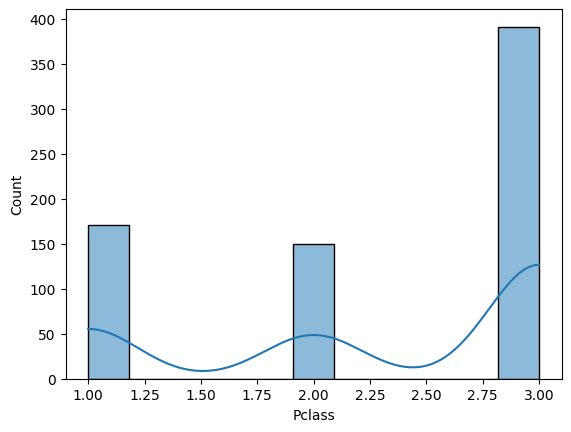

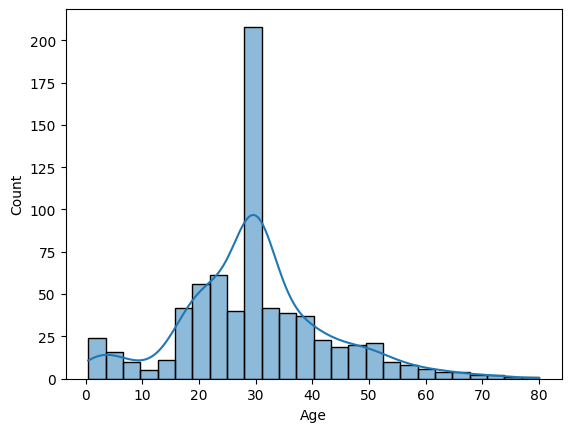

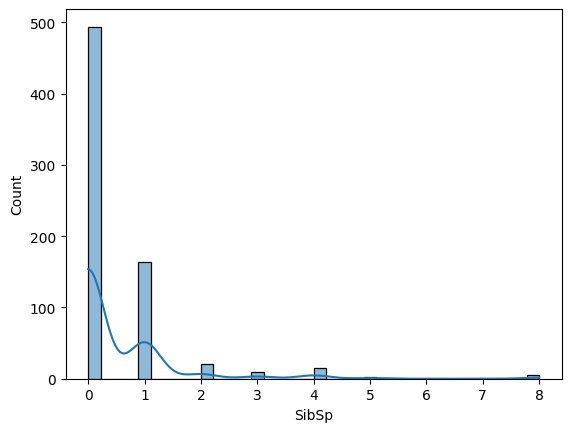

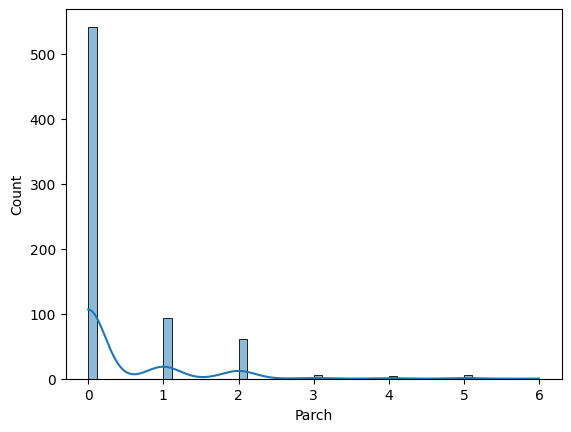

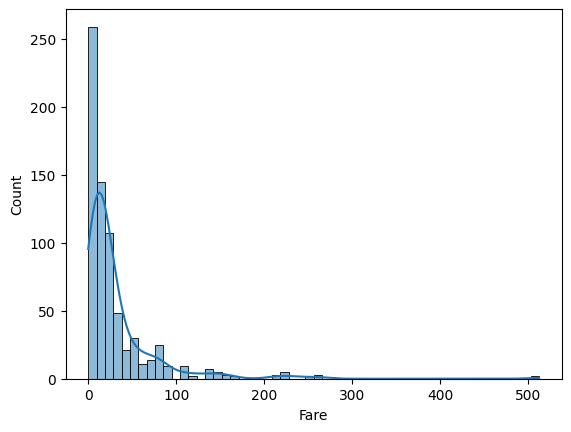

In [23]:
for name in X_train.columns:
    if X_train[name].dtype in ["int64" , "float64"]:
        sns.histplot(X_train[name] , kde=True)
        plt.show()

## 22. Transform Skewed Features

Apply `log1p(x)`, which calculates `log(1 + x)`, to `Fare`, `SibSp`, and `Parch` in both the training and test sets. The transformed values are stored in new `_log` columns; the original columns are retained.

In [24]:
###### handll Skew in Train #######
X_train["Fare_log"] = np.log1p(X_train["Fare"])
X_train["SibSp_log"] = np.log1p(X_train["SibSp"])
X_train["Parch_log"] = np.log1p(X_train["Parch"])

###### handll Skew in test ########
X_test["Fare_log"] = np.log1p(X_test["Fare"])
X_test["SibSp_log"] = np.log1p(X_test["SibSp"])
X_test["Parch_log"] = np.log1p(X_test["Parch"])

## 23. Keep Original Columns

The drop statements in the next cell are commented out, so the original `Fare`, `SibSp`, and `Parch` columns remain alongside their log-transformed versions.

In [25]:
# X_train.drop(columns=["SibSp" , "Parch" , "Fare"] , inplace=True)
# X_test.drop(columns=["SibSp" , "Parch" , "Fare"] , inplace=True)

## 24. Compare Skewness After Transformation

Calculate skewness for `Fare_log`, `Parch_log`, and `SibSp_log` in the training data and compare the values with the original skewness results.

In [26]:
col_skew = ["Fare_log" , "Parch_log" , "SibSp_log"]
print("After skew:")

print(X_train[col_skew].skew())

After skew:
Fare_log     0.312461
Parch_log    1.716580
SibSp_log    1.715546
dtype: float64


## 25. Review Transformed Distributions

Plot histograms of the log-transformed training features to visually inspect how their distributions changed.

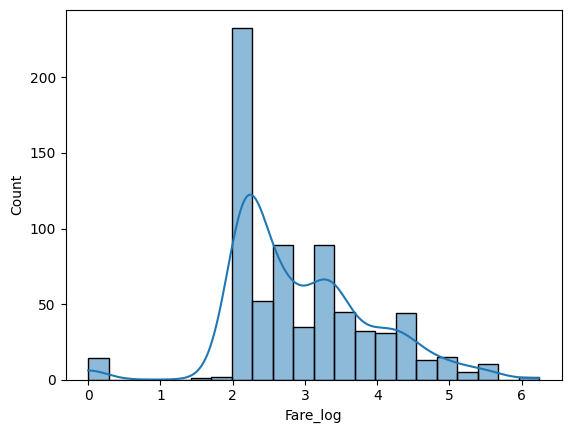

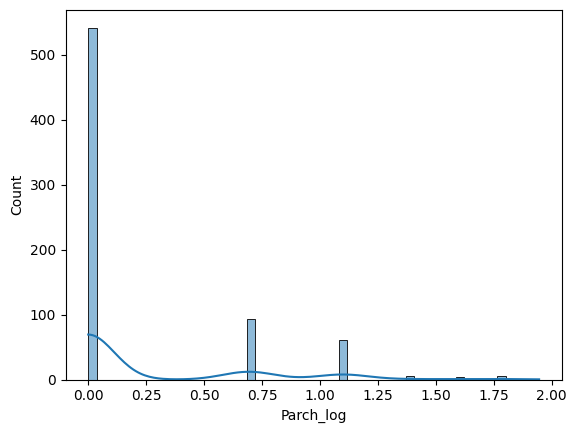

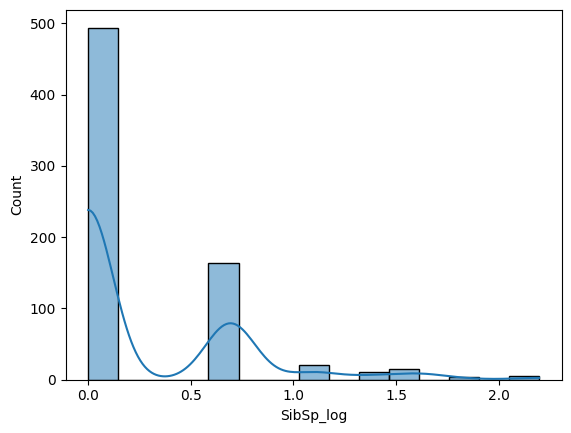

In [27]:
for name in col_skew:
    
    sns.histplot(X_train[name] , kde=True)
    plt.show()

In [28]:
X_train["Parch_log"].value_counts()

Parch_log
0.000000    542
0.693147     94
1.098612     61
1.791759      5
1.386294      5
1.609438      4
1.945910      1
Name: count, dtype: int64

## 26. Create New Features

Create `FamilySize` from the original `SibSp` and `Parch` columns, `IsAlone` to indicate whether the passenger travelled alone, and `FarePerPerson` by dividing the original `Fare` by `FamilySize`. These features are created after the log columns and IQR bounds have been calculated, but they use the original columns rather than the log-transformed values.

In [29]:
# Feature Engineering on X_train
X_train["FamilySize"] = (
    X_train["SibSp"] + X_train["Parch"] + 1
)

X_train["IsAlone"] = (
    X_train["FamilySize"] == 1
).astype(int)

X_train["FarePerPerson"] = (
    X_train["Fare"] /
    X_train["FamilySize"]
)


# Feature Engineering on X_test
X_test["FamilySize"] = (
    X_test["SibSp"] + X_test["Parch"] + 1
)

X_test["IsAlone"] = (
    X_test["FamilySize"] == 1
).astype(int)

X_test["FarePerPerson"] = (
    X_test["Fare"] /
    X_test["FamilySize"]
)

## 27. Select Numeric Columns

Select all numeric training columns for IQR-based outlier inspection. This list includes numeric features and their log-transformed versions; the later clipping step is restricted to `Fare` only.

In [30]:
numerical_columns = X_train.select_dtypes(include=[np.number]).columns
print(f"numerical columns:{numerical_columns}")

numerical columns:Index(['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Fare_log', 'SibSp_log',
       'Parch_log', 'FamilySize', 'IsAlone', 'FarePerPerson'],
      dtype='object')


In [31]:
X_train["FarePerPerson"].value_counts()

FarePerPerson
13.0000    48
8.0500     35
7.8958     32
7.7500     25
10.5000    23
           ..
5.0000      1
28.7125     1
53.2125     1
8.1375      1
38.5000     1
Name: count, Length: 254, dtype: int64

## 28. Calculate Quartiles and IQR

For each selected numeric training column, calculate the first quartile (`Q1`), third quartile (`Q3`), and interquartile range (`IQR = Q3 - Q1`).

In [32]:
Q1 = X_train[numerical_columns].quantile(0.25)
Q3 = X_train[numerical_columns].quantile(0.75)
IQR = Q3 - Q1



## 29. Define Outlier Bounds

Use the IQR rule to calculate lower and upper bounds: `Q1 - 1.5 × IQR` and `Q3 + 1.5 × IQR`. Values outside these bounds are potential outliers, not necessarily data errors.

In [33]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [34]:
print(X_train["FarePerPerson"].value_counts())
print(upper_bound)
print(lower_bound)

FarePerPerson
13.0000    48
8.0500     35
7.8958     32
7.7500     25
10.5000    23
           ..
5.0000      1
28.7125     1
53.2125     1
8.1375      1
38.5000     1
Name: count, Length: 254, dtype: int64
Pclass            4.500000
Age              57.000000
SibSp             2.500000
Parch             0.000000
Fare             65.656300
Fare_log          5.385971
SibSp_log         1.732868
Parch_log         0.000000
FamilySize        3.500000
IsAlone           2.500000
FarePerPerson    40.328125
dtype: float64
Pclass            0.500000
Age               1.000000
SibSp            -1.500000
Parch             0.000000
Fare            -26.760500
Fare_log          0.265344
SibSp_log        -1.039721
Parch_log         0.000000
FamilySize       -0.500000
IsAlone          -1.500000
FarePerPerson   -12.596875
dtype: float64


## 30. Inspect Training Outliers

Check which training values fall below or above the IQR bounds. The bounds are calculated from the training set.

In [35]:
def Xtrain():
    for com in X_train[numerical_columns]:
        outliers_below = X_train[com] < lower_bound[com]
        outliers_above = X_train[com] > upper_bound[com]
        if outliers_below.any():
            print(f"outliers below lower bound in columns : {com}")
            print(X_train.loc[outliers_below , com])

        elif outliers_above.any():
            print(f"outliers above upper bound in columns : {com}")
            print(X_train.loc[outliers_above , com])
        else:
            print(f"no outliers in column : {com}")
            continue
def Xtest():
    for com in X_test[numerical_columns]:
        outliers_below = X_test[com] < lower_bound[com]
        outliers_above = X_test[com] > upper_bound[com]
        if outliers_below.any():
            print(f"outliers below lower bound in columns : {com}")
            print(X_test.loc[outliers_below , com])
        elif outliers_above.any():
            print(f"outliers above upper bound in columns : {com}")
            print(X_test.loc[outliers_above , com])
        else:
            print(f"no outliers in column : {com}")
            continue


Xtrain()                         

no outliers in column : Pclass
outliers below lower bound in columns : Age
469    0.75
78     0.83
803    0.42
755    0.67
831    0.83
305    0.92
Name: Age, dtype: float64
outliers above upper bound in columns : SibSp
846    8
409    3
63     3
819    3
686    4
278    4
50     4
261    4
792    8
159    8
480    5
266    4
374    3
176    3
7      3
164    4
201    8
119    4
85     3
59     5
542    4
24     3
787    4
233    4
171    4
813    4
850    4
863    8
683    5
229    3
182    4
642    3
68     4
Name: SibSp, dtype: int64
outliers above upper bound in columns : Parch
855    1
801    1
846    2
409    1
197    1
      ..
68     2
329    1
498    2
689    1
736    3
Name: Parch, Length: 170, dtype: int64
outliers above upper bound in columns : Fare
527    221.7792
557    227.5250
846     69.5500
412     90.0000
218     76.2917
         ...   
498    151.5500
689    211.3375
665     73.5000
544    106.4250
258    512.3292
Name: Fare, Length: 91, dtype: float64
outliers below

## 31. Inspect Test Outliers

Check test values against the bounds calculated from the training data. This step reports potential outliers; it does not modify the values.

In [36]:
Xtest()

no outliers in column : Pclass
outliers below lower bound in columns : Age
644    0.75
Name: Age, dtype: float64
outliers above upper bound in columns : SibSp
27     3
485    3
71     5
180    8
634    3
386    5
341    3
324    8
16     4
726    3
541    4
824    4
88     3
Name: SibSp, dtype: int64
outliers above upper bound in columns : Parch
160    1
698    1
817    1
27     2
485    1
580    1
279    1
65     1
489    1
869    1
165    2
71     2
417    2
745    1
297    2
644    1
679    1
472    2
593    2
153    2
180    2
634    2
386    2
853    1
341    2
324    2
659    2
16     1
541    2
824    1
799    1
549    1
435    2
802    2
532    1
587    1
88     2
823    1
685    2
879    1
530    1
880    1
637    1
Name: Parch, dtype: int64
outliers above upper bound in columns : Fare
698    110.8833
27     263.0000
369     69.3000
730    211.3375
745     71.0000
297    151.5500
759     86.5000
679    512.3292
375     82.1708
275     77.9583
504     86.5000
180     69.5500
62

## 32. Treat Outliers

The current code clips `Fare` to its IQR bounds in both training and test sets. It does not clip every numeric column; `Age`, `Parch`, and `Pclass` are not directly clipped by this step.

In [37]:
X_train["Fare"] = np.where(X_train["Fare"] < lower_bound["Fare"] , lower_bound["Fare"] , np.where(X_train["Fare"] > upper_bound["Fare"] , upper_bound["Fare"] , X_train["Fare"]))


X_test["Fare"] = np.where(X_test["Fare"] < lower_bound["Fare"] , lower_bound["Fare"] , np.where(X_test["Fare"] > upper_bound["Fare"] , upper_bound["Fare"] , X_test["Fare"]))
        

## 33. One-Hot Encode Embarked

`OneHotEncoder` converts the categorical `Embarked` column into indicator columns. The encoder is fitted on training data and then reused to transform test data, with unknown categories handled safely.

In [38]:
cat_col = ["Embarked"]
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_one = encoder.fit_transform(X_train[cat_col])
X_test_one = encoder.transform(X_test[cat_col])

encoded_cols = encoder.get_feature_names_out(cat_col)

X_train_one = pd.DataFrame(
    X_train_one,
    columns=encoded_cols,
    index=X_train.index
)

X_test_one = pd.DataFrame(
    X_test_one,
    columns=encoded_cols,
    index=X_test.index
)

X_train = pd.concat([X_train.drop(columns=cat_col) , X_train_one] , axis=1)
X_test = pd.concat([X_test.drop(columns=cat_col) , X_test_one] , axis=1)

## 34. Preview Encoded Features

Display the training features after encoding `Embarked` to check the resulting columns and values.

In [39]:
X_train.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Fare_log,SibSp_log,Parch_log,FamilySize,IsAlone,FarePerPerson,Embarked_C,Embarked_Q,Embarked_S
692,3,male,29.807687,0,0,56.4958,4.051712,0.000000,0.000000,1,1,56.4958,0.0,0.0,1.0
481,2,male,29.807687,0,0,0.0000,0.000000,0.000000,0.000000,1,1,0.0000,0.0,0.0,1.0
527,1,male,29.807687,0,0,65.6563,5.406181,0.000000,0.000000,1,1,221.7792,0.0,0.0,1.0
855,3,female,18.000000,0,1,9.3500,2.336987,0.000000,0.693147,2,0,4.6750,0.0,0.0,1.0
801,2,female,31.000000,1,1,26.2500,3.305054,0.693147,0.693147,3,0,8.7500,0.0,0.0,1.0


## 35. Encode Remaining Categorical Features

Use `OrdinalEncoder` to convert any remaining object-type columns into numeric values. Fit the encoder on training data and reuse it for the test data; unseen test categories are assigned `-1`.

In [40]:
cat_cols = X_train.select_dtypes(include="object").columns
enc = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_train[cat_cols] = enc.fit_transform(X_train[cat_cols])
X_test[cat_cols] = enc.transform(X_test[cat_cols])

## 36. Check Data Types

Use `info()` to review the feature data types and non-null counts after preprocessing and encoding.

In [41]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 692 to 507
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pclass         712 non-null    int64  
 1   Sex            712 non-null    float64
 2   Age            712 non-null    float64
 3   SibSp          712 non-null    int64  
 4   Parch          712 non-null    int64  
 5   Fare           712 non-null    float64
 6   Fare_log       712 non-null    float64
 7   SibSp_log      712 non-null    float64
 8   Parch_log      712 non-null    float64
 9   FamilySize     712 non-null    int64  
 10  IsAlone        712 non-null    int64  
 11  FarePerPerson  712 non-null    float64
 12  Embarked_C     712 non-null    float64
 13  Embarked_Q     712 non-null    float64
 14  Embarked_S     712 non-null    float64
dtypes: float64(10), int64(5)
memory usage: 89.0 KB


## 37. Preview Test Features

Inspect the test features after preprocessing and check that the columns are consistent with the training features.

In [42]:
X_test.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Fare_log,SibSp_log,Parch_log,FamilySize,IsAlone,FarePerPerson,Embarked_C,Embarked_Q,Embarked_S
565,3,1.0,24.000000,2,0,24.1500,3.224858,1.098612,0.000000,3,0,8.050000,0.0,0.0,1.0
160,3,1.0,44.000000,0,1,16.1000,2.839078,0.000000,0.693147,2,0,8.050000,0.0,0.0,1.0
553,3,1.0,22.000000,0,0,7.2250,2.107178,0.000000,0.000000,1,1,7.225000,1.0,0.0,0.0
860,3,1.0,41.000000,2,0,14.1083,2.715244,1.098612,0.000000,3,0,4.702767,0.0,0.0,1.0
241,3,0.0,29.807687,1,0,15.5000,2.803360,0.693147,0.000000,2,0,7.750000,0.0,1.0,0.0


## 38. Check Class Distribution

Compare the `Survived` counts in the training and test targets. The split uses `stratify=y` to preserve approximately the same class proportions in both sets.

In [43]:
print(y_train.value_counts())
print(y_test.value_counts())

Survived
0    439
1    273
Name: count, dtype: int64
Survived
0    110
1     69
Name: count, dtype: int64


## 39. Balance the Training Classes with SMOTE

SMOTE creates synthetic examples for the minority class to balance the training target. It is applied only to `X_train` and `y_train`; the test set remains unchanged. The print statement in the following cell runs after resampling, so it displays the class counts after SMOTE, despite the text label saying “Before smote”.

In [44]:
smote = SMOTE(random_state=42)

X_train , y_train = smote.fit_resample(X_train , y_train)

print("Befor smote :" , y_train.value_counts())

Befor smote : Survived
1    439
0    439
Name: count, dtype: int64


## 40. Scale Numeric Features

`StandardScaler` standardizes features using the mean and standard deviation learned from the training data. The fitted scaler is then applied to the test data without refitting, keeping the test set separate from training-time preprocessing.

In [45]:
stnd = StandardScaler()
X_train_stn = stnd.fit_transform(X_train)
X_test_stn = stnd.transform(X_test)

## 41. Train and Evaluate Models

Train each classifier using the scaled training features, then evaluate it on the unchanged test set. The notebook reports training and test accuracy, a classification report, and a confusion matrix for each model.

In [46]:
list_acc = {}
train_acc = {}

models = {
    "logistic_regression" : LogisticRegression(max_iter=2000,
                                               C=1.0),
    "Decision_tree" : DecisionTreeClassifier(
        max_depth=7,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
        
    ),
    "Random_Forest" : RandomForestClassifier(
        n_estimators=150,
        max_depth=5,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
        
    
    ),
    "KNN" : KNeighborsClassifier(
        n_neighbors=7,
        weights="distance"
        

    )
}

for name , model in  models.items():
    model.fit(X_train_stn,y_train)
    y_pre = model.predict(X_test_stn)
    acc = accuracy_score(y_test , y_pre)
    print(f"accuracy_score test {name}: {acc}")
    list_acc[name] = acc
    y_prd = model.predict(X_train_stn)
    acc_train = accuracy_score(y_train , y_prd)
    print(f"accuracy_score trian {name} : {acc_train}")
    train_acc[name] = acc_train

    print(f"\nClassification Report {name}:")
    print(classification_report(y_test, y_pre ))

    print(f"Confusion Matrix {name}:")
    print(confusion_matrix(y_test, y_pre))

acc_befor = pd.DataFrame({
    "acc_test" : list_acc,
    "acc_train" : train_acc

})
print(acc_befor)

   

accuracy_score test logistic_regression: 0.8212290502793296
accuracy_score trian logistic_regression : 0.8086560364464692

Classification Report logistic_regression:
              precision    recall  f1-score   support

           0       0.87      0.84      0.85       110
           1       0.75      0.80      0.77        69

    accuracy                           0.82       179
   macro avg       0.81      0.82      0.81       179
weighted avg       0.82      0.82      0.82       179

Confusion Matrix logistic_regression:
[[92 18]
 [14 55]]
accuracy_score test Decision_tree: 0.770949720670391
accuracy_score trian Decision_tree : 0.8895216400911162

Classification Report Decision_tree:
              precision    recall  f1-score   support

           0       0.79      0.85      0.82       110
           1       0.73      0.64      0.68        69

    accuracy                           0.77       179
   macro avg       0.76      0.75      0.75       179
weighted avg       0.77      0.

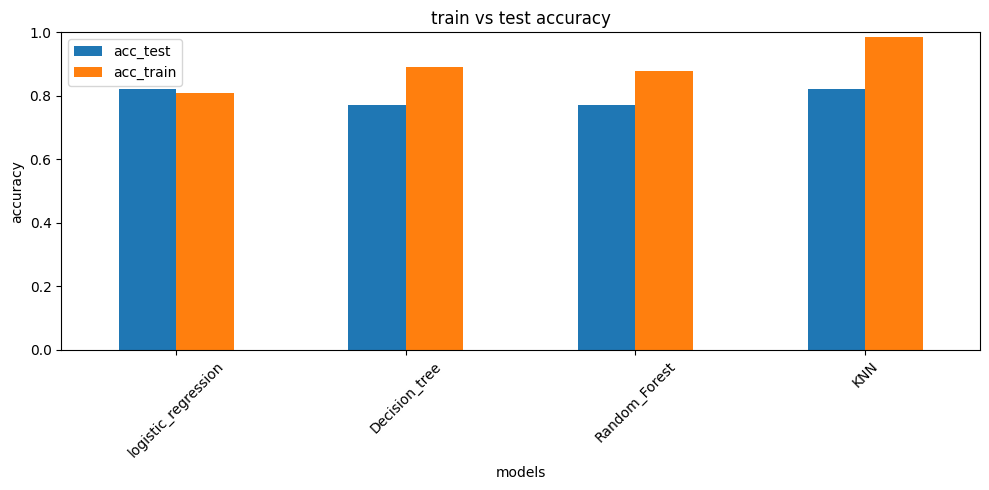

In [47]:
acc_befor.plot(kind="bar" , figsize=(10,5))

plt.title("train vs test accuracy")
plt.ylabel("accuracy")
plt.xlabel("models")
plt.ylim(0,1)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()